# Calories burnt prediction
### A simple walkthrough from data exploration to model comparison

This notebook compares Linear Regression, Lasso, Ridge and XGBoost for predicting
the `Calories` column in a supplied exercise dataset. It then tunes XGBoost,
looks at its explanations and errors, and saves a model for the optional desktop GUI.

This notebook has its own simple train/test split and computed results.
The more extensive [research project](https://github.com/Moobakr/calorie-lab-research)
is maintained separately.

Run the cells from top to bottom. Change `data_path` below if your CSV is elsewhere.

## 1. Objective and dataset

The inputs are recorded gender, age, height, weight, workout duration, heart rate
and body temperature. The target is the recorded calorie label. `User_ID` is an
identifier and will not be used to predict calories.

The dataset's original collection, label construction, units and licensing are
unverified. We interpret the target as kcal per session for this example; low
prediction error does not establish accurate measurement of physical calorie burn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

In [2]:
data_path = "exercise.csv"  # CSV included beside this notebook.
calories_data = pd.read_csv(data_path)

print("Dataset shape:", calories_data.shape)
calories_data.head()

Dataset shape: (15000, 9)


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190,94,29,105,40.8,231
1,14861698,female,20,166,60,14,94,40.3,66
2,11179863,male,69,179,79,5,88,38.7,26
3,16180408,female,34,179,71,13,100,40.5,71
4,17771927,female,27,154,58,10,81,39.8,35


## 2. Data checks

Check the column types, missing values and summary statistics before training.
We also remove `User_ID` and repeated observations so an identical record cannot
appear on both sides of the split. No missing-value filling is needed for the supplied CSV.

In [3]:
calories_data.info()
calories_data.isnull().sum().to_frame("Missing values")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  int64  
 4   Weight      15000 non-null  int64  
 5   Duration    15000 non-null  int64  
 6   Heart_Rate  15000 non-null  int64  
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  int64  
dtypes: float64(1), int64(7), object(1)
memory usage: 1.0+ MB


,Missing values
User_ID,0
Gender,0
Age,0
Height,0
Weight,0
Duration,0
Heart_Rate,0
Body_Temp,0
Calories,0


In [4]:
calories_data = calories_data.drop(columns="User_ID")
print("Duplicate observations:", calories_data.duplicated().sum())

calories_data = calories_data.drop_duplicates().copy()
print("Shape after removing duplicates:", calories_data.shape)
calories_data.describe()

Duplicate observations: 1
Shape after removing duplicates: (14999, 8)


,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,42.790786,174.465831,74.967931,15.531035,95.518901,40.025488,89.542836
std,16.980401,14.258333,15.035593,8.319310,9.583542,0.779244,62.457750
min,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


## 3. Exploratory analysis

Use a few plots to understand the data. Relationships in these records are
descriptive associations, not evidence that changing an input causes calorie burn to change.

### Recorded gender and numeric distributions

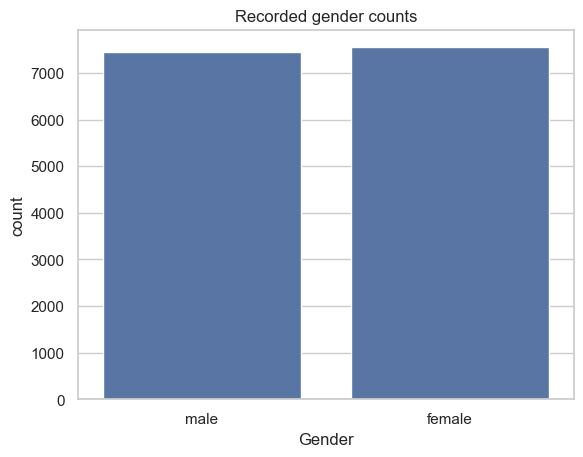

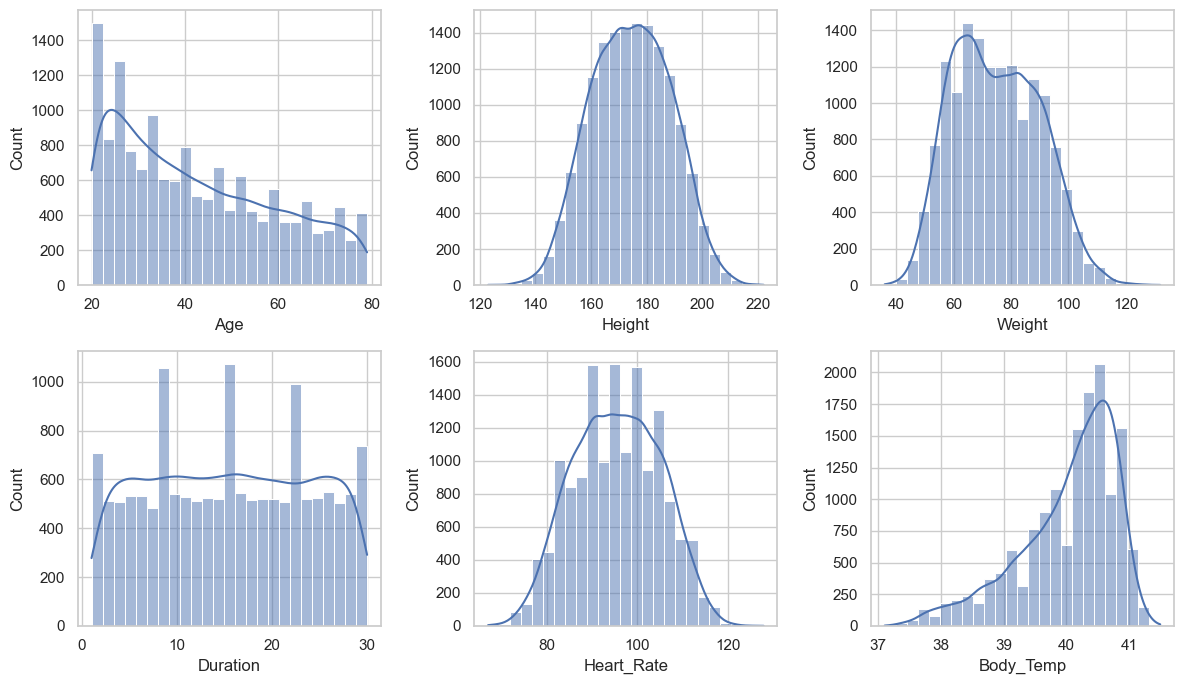

In [5]:
sns.countplot(data=calories_data, x="Gender")
plt.title("Recorded gender counts")
plt.show()

columns = ["Age", "Height", "Weight", "Duration", "Heart_Rate", "Body_Temp"]
plt.figure(figsize=(12, 7))
for i, column in enumerate(columns):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data=calories_data, x=column, bins=25, kde=True)
plt.tight_layout()
plt.show()

### Inputs and the calorie label

The same random sample is used in all four scatter plots to keep the comparison consistent.

The scatter plots show clearer relationships with duration and heart rate than with weight alone. The following heatmap summarizes linear associations across the numeric columns.

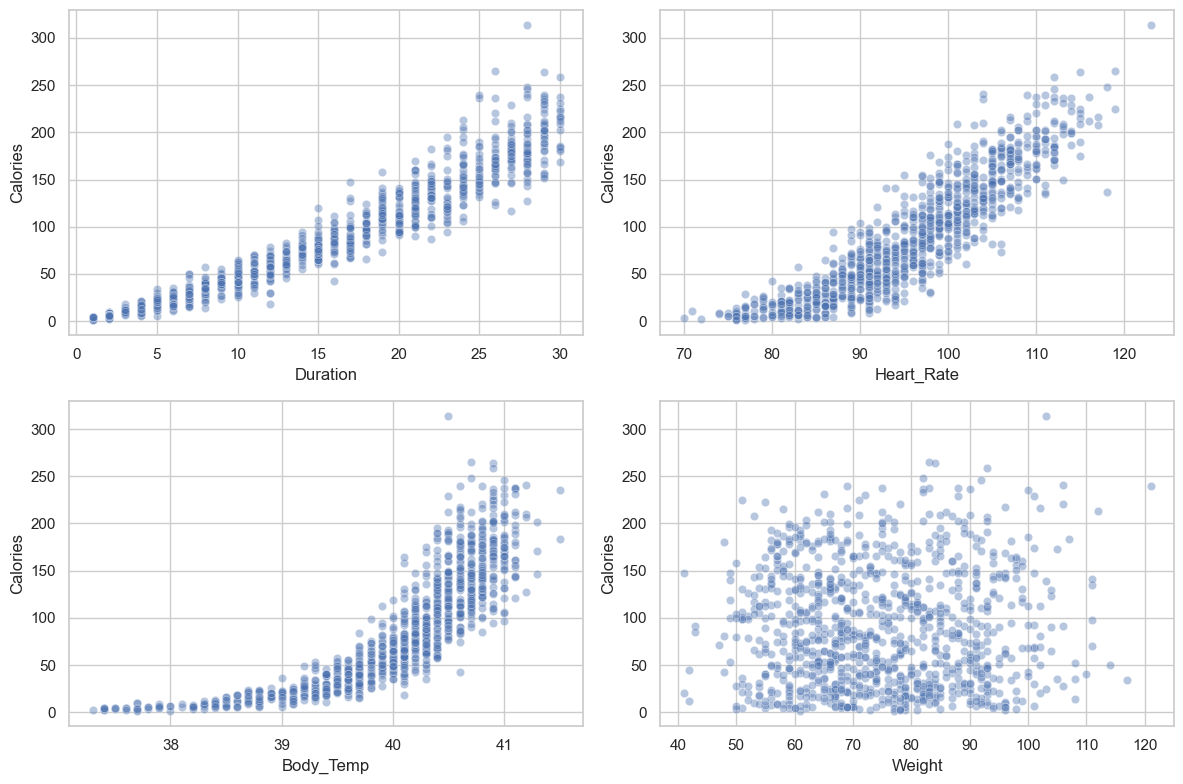

In [6]:
sample_data = calories_data.sample(1000, random_state=2)
features = ["Duration", "Heart_Rate", "Body_Temp", "Weight"]

plt.figure(figsize=(12, 8))
for i, column in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.scatterplot(data=sample_data, x=column, y="Calories", alpha=0.4)
plt.tight_layout()
plt.show()

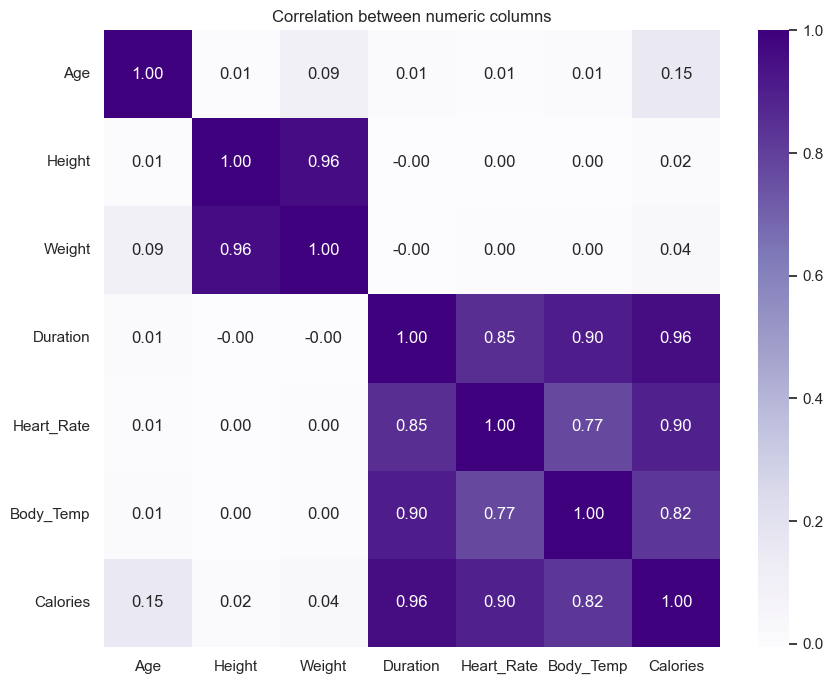

In [7]:
correlation = calories_data.drop(columns="Gender").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="Purples")
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

## 4. Train/test preparation

Keep the original notebook's 80/20 split ratio and random seed of 2. Removing the duplicate changes the actual rows in each partition. Encode the two
recorded gender categories as before. Each model gets the same rows.

Scaling happens inside each pipeline, using training rows only. We pass the
original input values to the pipelines instead of scaling them a second time.

In [8]:
calories_data["Gender"] = calories_data["Gender"].map({"male": 0, "female": 1})

X = calories_data.drop(columns="Calories")
Y = calories_data["Calories"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Input columns:", list(X.columns))

Training rows: 11999
Test rows: 3000
Input columns: ['Gender', 'Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp']


## 5. Model comparison

Train the same four model families as the original notebook. The code for each
model follows the same steps: create a pipeline, fit it, predict and calculate errors.

**MAE** is the average absolute difference between predictions and recorded labels.
**RMSE** gives more weight to large errors. Lower values are better. Training and
test MAE are shown together to help spot a large generalization gap.

### Linear Regression

In [9]:
lr_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", LinearRegression())
])
lr_pipeline.fit(X_train, Y_train)

lr_train_predictions = lr_pipeline.predict(X_train)
lr_test_predictions = lr_pipeline.predict(X_test)

lr_train_mae = mean_absolute_error(Y_train, lr_train_predictions)
lr_test_mae = mean_absolute_error(Y_test, lr_test_predictions)
lr_test_rmse = np.sqrt(mean_squared_error(Y_test, lr_test_predictions))

### Lasso

In [10]:
lasso_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", Lasso())
])
lasso_pipeline.fit(X_train, Y_train)

lasso_train_predictions = lasso_pipeline.predict(X_train)
lasso_test_predictions = lasso_pipeline.predict(X_test)

lasso_train_mae = mean_absolute_error(Y_train, lasso_train_predictions)
lasso_test_mae = mean_absolute_error(Y_test, lasso_test_predictions)
lasso_test_rmse = np.sqrt(mean_squared_error(Y_test, lasso_test_predictions))

### Ridge

In [11]:
ridge_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", Ridge())
])
ridge_pipeline.fit(X_train, Y_train)

ridge_train_predictions = ridge_pipeline.predict(X_train)
ridge_test_predictions = ridge_pipeline.predict(X_test)

ridge_train_mae = mean_absolute_error(Y_train, ridge_train_predictions)
ridge_test_mae = mean_absolute_error(Y_test, ridge_test_predictions)
ridge_test_rmse = np.sqrt(mean_squared_error(Y_test, ridge_test_predictions))

### XGBoost

In [12]:
xgb_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", XGBRegressor(random_state=2, n_jobs=1))
])
xgb_pipeline.fit(X_train, Y_train)

xgb_train_predictions = xgb_pipeline.predict(X_train)
xgb_test_predictions = xgb_pipeline.predict(X_test)

xgb_train_mae = mean_absolute_error(Y_train, xgb_train_predictions)
xgb_test_mae = mean_absolute_error(Y_test, xgb_test_predictions)
xgb_test_rmse = np.sqrt(mean_squared_error(Y_test, xgb_test_predictions))

### Compare the results

In [13]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Lasso", "Ridge", "XGBoost"],
    "Train MAE": [lr_train_mae, lasso_train_mae, ridge_train_mae, xgb_train_mae],
    "Test MAE": [lr_test_mae, lasso_test_mae, ridge_test_mae, xgb_test_mae],
    "Test RMSE": [lr_test_rmse, lasso_test_rmse, ridge_test_rmse, xgb_test_rmse]
})
results.round(3)

,Model,Train MAE,Test MAE,Test RMSE
0,Linear Regression,8.359,8.335,11.308
1,Lasso,10.644,10.500,15.086
2,Ridge,8.353,8.331,11.313
3,XGBoost,0.899,1.367,1.977


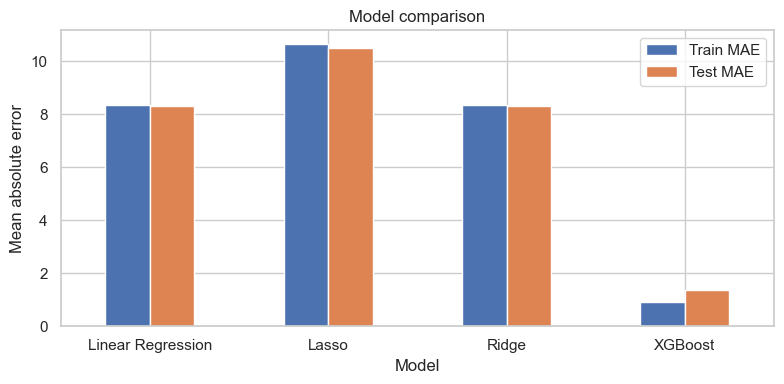

In [14]:
results.plot(x="Model", y=["Train MAE", "Test MAE"], kind="bar", figsize=(8, 4))
plt.ylabel("Mean absolute error")
plt.title("Model comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. XGBoost tuning

Use the original notebook's GridSearchCV approach with a smaller grid: eight
combinations and five folds, giving 40 cross-validation fits. This keeps the
example manageable. The grid is scored by MAE, matching our comparison table.

The search uses training rows only. The tuned model is then evaluated on the
same test split used above. This is an exploratory comparison, not fresh external validation.

In [15]:
param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1]
}

grid_search = GridSearchCV(
    xgb_pipeline, param_grid, cv=5,
    scoring="neg_mean_absolute_error", n_jobs=1
)
grid_search.fit(X_train, Y_train)

best_xgb_pipeline = grid_search.best_estimator_
print("Best settings:", grid_search.best_params_)
print("Cross-validation MAE:", round(-grid_search.best_score_, 3))

Best settings: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300}
Cross-validation MAE: 1.127


In [16]:
tuned_train_predictions = best_xgb_pipeline.predict(X_train)
tuned_test_predictions = best_xgb_pipeline.predict(X_test)

tuned_train_mae = mean_absolute_error(Y_train, tuned_train_predictions)
tuned_test_mae = mean_absolute_error(Y_test, tuned_test_predictions)
tuned_test_rmse = np.sqrt(mean_squared_error(Y_test, tuned_test_predictions))

results.loc[len(results)] = [
    "Tuned XGBoost", tuned_train_mae, tuned_test_mae, tuned_test_rmse
]
results.round(3)

,Model,Train MAE,Test MAE,Test RMSE
0,Linear Regression,8.359,8.335,11.308
1,Lasso,10.644,10.500,15.086
2,Ridge,8.353,8.331,11.313
3,XGBoost,0.899,1.367,1.977
4,Tuned XGBoost,0.809,1.034,1.476


## 7. Explanation and error analysis

### Which inputs influence the tuned model?

Use SHAP with the tuned model and its matching scaler. To keep the plot quick,
explain the first 200 test rows. The bars show average absolute contribution to
the model's predictions on that subset. They are not causal effects or universal importance rankings.

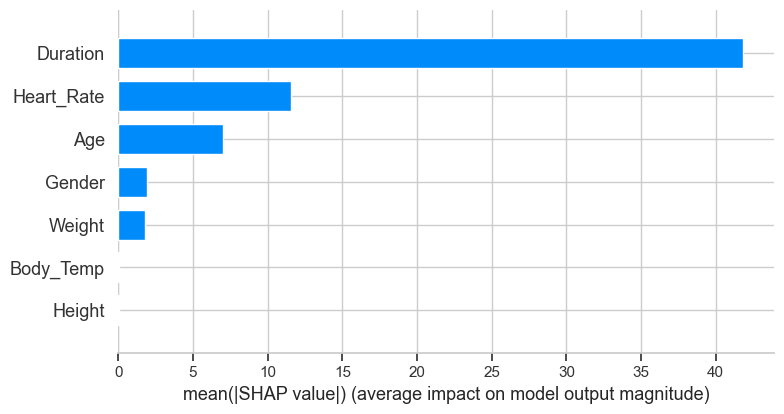

In [17]:
best_model = best_xgb_pipeline.named_steps["model"]
best_scaler = best_xgb_pipeline.named_steps["scaler"]
X_explain = best_scaler.transform(X_test.iloc[:200])

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_explain)
shap.summary_plot(shap_values, X_explain, feature_names=X.columns, plot_type="bar")

### Where does the model make errors?

Plot actual minus predicted labels. Positive errors mean the model underestimated;
negative errors mean it overestimated. Wider spread means larger errors.

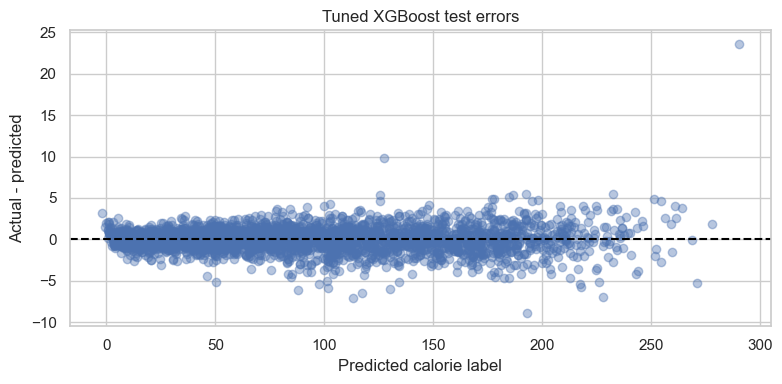

In [18]:
errors = Y_test - tuned_test_predictions

plt.figure(figsize=(8, 4))
plt.scatter(tuned_test_predictions, errors, alpha=0.4)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted calorie label")
plt.ylabel("Actual - predicted")
plt.title("Tuned XGBoost test errors")
plt.tight_layout()
plt.show()

### Save the model for the optional GUI

The desktop GUI lives in `calorie_calculator.py` so running the notebook does not
open a window or block execution. It loads this exact tuned pipeline without retraining.
Run `python calorie_calculator.py` from this notebook's folder after running all cells.
Only load the model file generated by this notebook.

In [19]:
joblib.dump(best_xgb_pipeline, "calorie_model.joblib")
print("Saved calorie_model.joblib for the optional GUI.")

Saved calorie_model.joblib for the optional GUI.


## 8. Findings and limitations

- Use the results table to compare the four starting models and tuned XGBoost.
- Compare training and test errors; a low training error alone is not sufficient.
- Use the SHAP plot and error plot to explain the selected model beyond one score.
- These are newly computed results for this revised example, not the original notebook's saved scores.

This is a simple exploratory study of a previously examined dataset. Unknown
data collection, label construction, units and possible dependence between
records limit interpretation. There is no independent physiological validation
or measured user benefit. The separate research repository contains the more
controlled input-comparison and reliability study; its frozen results are unchanged.

### Results from this run

The tuned XGBoost model has training MAE **0.809**, test MAE **1.034** and test RMSE **1.476** on 3,000 test records. Compare its row with the untuned models rather than assuming tuning always helps. These scores belong only to this revised exploratory notebook.
